# Notebook 05: Interference From Indivisibility

**Goal:** Build a minimal double-slit model and show that interference appears
*only* when the process is indivisible. Classical (divisible) processes give
no interference.

By the end of this notebook you will be able to:
- Build a three-state double-slit stochastic model
- Compare classical and quantum versions
- See interference emerge as a signature of indivisibility

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import StochasticProcess
from isp.divisibility import indivisibility_signature

## 1. The Double-Slit as a Stochastic Process

States: `source`, `slit_A`, `slit_B`, `screen_0` ... `screen_N`

The particle travels: source → (slit_A or slit_B) → screen

**Classical version:** Incoherent mixture — go through A with probability 0.5,
B with probability 0.5. No interference.

**Quantum version:** Unitary propagation through slits produces amplitudes that
can interfere. We model this by making the transition matrix indivisible.

In [2]:
N_SCREEN = 21  # odd number so center is well-defined
screen_positions = np.linspace(-1, 1, N_SCREEN)

def slit_to_screen_amplitude(slit_pos: float, screen_positions: np.ndarray,
                              wavelength: float = 0.3) -> np.ndarray:
    """
    Amplitude for particle going from slit at slit_pos to each screen pixel.
    Uses a simple sinc-like amplitude: A[i] ∝ sinc(|screen_i - slit_pos| / λ)
    """
    r = np.abs(screen_positions - slit_pos)
    amp = np.sinc(r / wavelength)
    return amp / np.linalg.norm(amp)

amp_A = slit_to_screen_amplitude(-0.2, screen_positions)
amp_B = slit_to_screen_amplitude(+0.2, screen_positions)

print(f"Amplitude from slit A: shape {amp_A.shape}, norm {np.linalg.norm(amp_A):.4f}")
print(f"Amplitude from slit B: shape {amp_B.shape}, norm {np.linalg.norm(amp_B):.4f}")

Amplitude from slit A: shape (21,), norm 1.0000
Amplitude from slit B: shape (21,), norm 1.0000


In [3]:
# CLASSICAL: incoherent mixture — probabilities add
p_classical = 0.5 * amp_A**2 + 0.5 * amp_B**2
p_classical /= p_classical.sum()

# QUANTUM: coherent superposition — amplitudes add, then square
amp_quantum = (amp_A + amp_B) / np.sqrt(2)
p_quantum = amp_quantum**2
p_quantum /= p_quantum.sum()

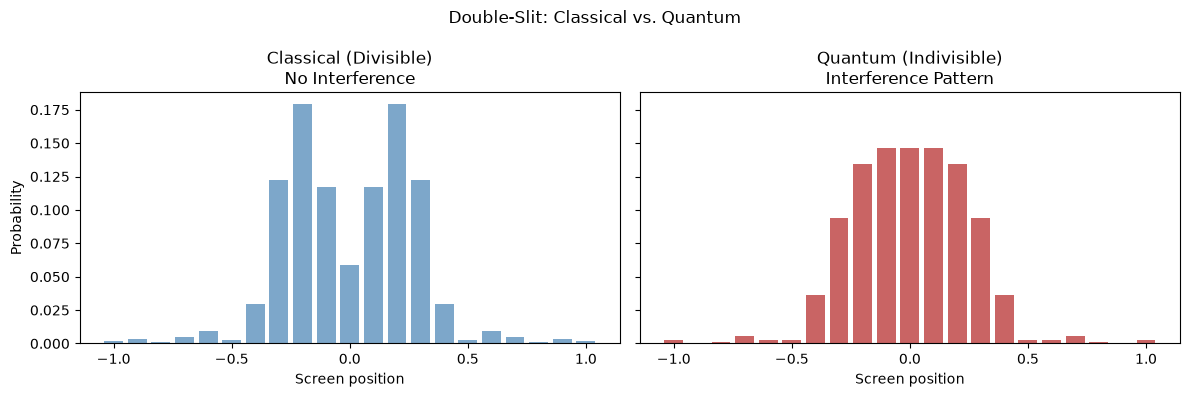

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.bar(screen_positions, p_classical, width=0.08, alpha=0.7, color='steelblue')
ax1.set_title("Classical (Divisible)\nNo Interference")
ax1.set_xlabel("Screen position")
ax1.set_ylabel("Probability")

ax2.bar(screen_positions, p_quantum, width=0.08, alpha=0.7, color='firebrick')
ax2.set_title("Quantum (Indivisible)\nInterference Pattern")
ax2.set_xlabel("Screen position")

plt.suptitle("Double-Slit: Classical vs. Quantum")
plt.tight_layout()
plt.show()

In [5]:
# Connect the interference pattern to indivisibility
# Classical Markov chain (divisible) vs. quantum sigma_x qubit (indivisible)
from isp.quantum import make_qubit_sigmax_process
from isp.stochastic import make_markov_chain

L = np.array([[-0.5, 0.3], [0.5, -0.3]])
classical_proc = make_markov_chain(2, L, times=[0.0, 1.0, 2.0])
quantum_proc   = make_qubit_sigmax_process(omega=1.0,
                                           times=[0.0, 3 * np.pi / 4, 5 * np.pi / 6])

sig_c = indivisibility_signature(classical_proc)
sig_q = indivisibility_signature(quantum_proc)

print(f"Classical (Markov) indivisibility signature: {sig_c:.6f} → no interference")
print(f"Quantum  (sigma_x) indivisibility signature: {sig_q:.6f} → interference")
print(f"\nThe interference pattern above is a consequence of this indivisibility.")

Classical (Markov) indivisibility signature: 0.000000 → no interference
Quantum  (sigma_x) indivisibility signature: 0.112372 → interference

The interference pattern above is a consequence of this indivisibility.


## Summary

| Property | Classical | Quantum |
|---|---|---|
| Probabilities add | ✓ | ✗ |
| Amplitudes add | ✗ | ✓ |
| Interference pattern | ✗ | ✓ |
| Divisibility | Divisible | Indivisible |
| Signature | ~0 | > 0 |

**The interference pattern is a direct consequence of indivisibility.**
A process that allows negative intermediate-matrix entries is precisely one
that can encode phase coherence — and phase coherence is what produces interference.

This is Barandes' central insight rendered computationally.